# V-JEPA 2 action-conditioned planning

Can a visual goal guide a short plan after a video encoder learns without actions? Pretrain on unlabelled clips, freeze the encoder and fit an action-conditioned model of motion on a small grid.

This CPU exercise follows the two-stage idea in V-JEPA 2-AC. Four rendered frames form two temporal tubelets. A small MLP learns single-step latent dynamics and an exhaustive three-action search selects a plan. All weights are trained here. The published system uses large video backbones, robot trajectories and a different search procedure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)


import copy
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "video_teaching.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Representation Learning folder.")
from gallery.video_teaching import (
    VideoEncoder,
    VideoPredictor,
    advance,
    clips,
    frame,
    region_mask,
    tubelets,
    update_teacher,
)

from itertools import product
from sklearn.decomposition import PCA


class Dynamics(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.delta = nn.Sequential(
            nn.Linear(width + 4, 96),
            nn.GELU(),
            nn.Linear(96, 96),
            nn.GELU(),
            nn.Linear(96, width),
        )

    def forward(self, state, action):
        u = F.one_hot(action, num_classes=4).float()
        return state + self.delta(torch.cat([state, u], dim=-1))


def state_id(xy):
    return 7 * xy[..., 0] + xy[..., 1]


def roll(start, actions):
    xy = start
    for a in actions.T:
        xy = advance(xy, a)
    return xy

## Pretrain the visual features without actions

The online encoder sees visible tubelets, while its moving-average target sees the complete clip. Only hidden target features enter the objective.

In [2]:
seed()
train = tubelets(clips(512, 17))
online = VideoEncoder()
teacher = copy.deepcopy(online).eval().requires_grad_(False)
predictor = VideoPredictor()
opt = torch.optim.AdamW([*online.parameters(), *predictor.parameters()], lr=0.0012)
rng = torch.Generator().manual_seed(31)
ssl = []
for epoch in range(9):
    values = []
    for ids in torch.randperm(len(train), generator=rng).split(48):
        keep, hide = region_mask(rng)
        p = train[ids]
        with torch.no_grad():
            goal = teacher(p)[-1][:, hide]
        estimate = predictor(online(p, keep), keep, hide)[0][:, len(keep) :]
        loss = F.l1_loss(estimate, goal)
        opt.zero_grad()
        loss.backward()
        opt.step()
        update_teacher(teacher, online)
        values.append((loss.item(), len(p)))
    ssl.append(sum(a * n for a, n in values) / len(train))

## Fit a frozen-space transition model

Each distinct position-action pair belongs to exactly one split. A PCA basis fitted to training-state encodings keeps the action model small. At planning time a still observation is presented as four copies of one frame.

In [3]:
states = torch.tensor(list(product(range(7), repeat=2)))
actions = torch.arange(4).repeat(len(states))
before = torch.arange(len(states)).repeat_interleave(4)
after = state_id(advance(states[before], actions))
order = torch.randperm(len(actions), generator=torch.Generator().manual_seed(97))
tr, te = order[:160], order[160:]
static = frame(states)[:, None].repeat(1, 4, 1, 1)
with torch.no_grad():
    visual = teacher(tubelets(static))[-1].flatten(1).numpy()
seen = torch.unique(torch.cat([before[tr], after[tr]])).numpy()
basis = PCA(10, whiten=True, svd_solver="full").fit(visual[seen])
latent = torch.tensor(basis.transform(visual).copy(), dtype=torch.float32)
model = Dynamics(latent.shape[1])
optim = torch.optim.AdamW(model.parameters(), lr=0.003, weight_decay=0.002)
for epoch in range(145):
    for ids in tr[torch.randperm(len(tr))].split(40):
        loss = F.smooth_l1_loss(model(latent[before[ids]], actions[ids]), latent[after[ids]])
        optim.zero_grad()
        loss.backward()
        optim.step()
model.eval()
with torch.no_grad():
    forecast = model(latent[before[te]], actions[te])
    actual = latent[after[te]]
    rows = []
    for name, z in [
        ("Keep current feature", latent[before[te]]),
        ("Action-conditioned", forecast),
    ]:
        nearest = torch.cdist(z, latent).argmin(1)
        rows.append(
            (
                name,
                len(te),
                float((z - actual).abs().mean()),
                float((nearest == after[te]).float().mean()),
            )
        )
report(
    ["Transition model", "Unseen state-action pairs", "Latent MAE", "Nearest-state accuracy"],
    rows,
)

,Transition model,Unseen state-action pairs,Latent MAE,Nearest-state accuracy
0,Keep current feature,36,0.48970,0.16667
1,Action-conditioned,36,0.15189,1.00000


## Plan towards held-out start-goal pairs

Draw distinct nontrivial pairs that can be connected in exactly three moves. The learned planner scores candidates only by predicted latent distance to the observed goal. The simulator supplies the evaluation and a reachable-goal reference.

,Planner,Goal pairs,Exact goal success,Mean final Manhattan distance
0,Random 3-step plan,80,0.05,2.2375
1,Latent planner,80,1.00,0.0000
2,Simulator oracle,80,1.00,0.0000


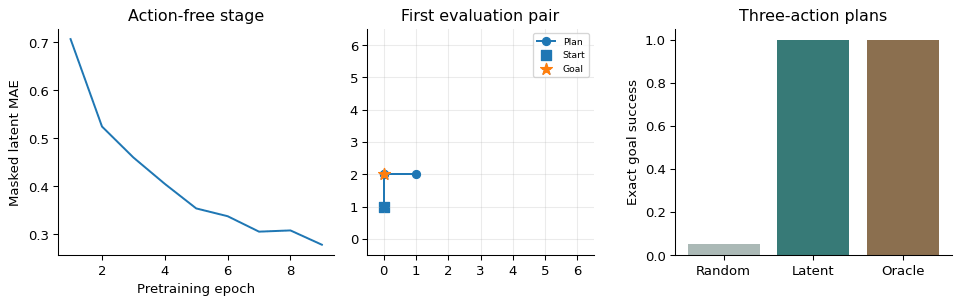

In [4]:
plans = torch.tensor(list(product(range(4), repeat=3)))
gen = torch.Generator().manual_seed(191)
pairs = []
while len(pairs) < 80:
    source = torch.randint(7, (1, 2), generator=gen)
    aim = roll(source, torch.randint(4, (1, 3), generator=gen))
    pair = (tuple(source[0].tolist()), tuple(aim[0].tolist()))
    if pair[0] != pair[1] and pair not in pairs:
        pairs.append(pair)
errors = [[], [], []]
with torch.no_grad():
    for idx, (source, goal) in enumerate(pairs):
        original = torch.tensor(source)
        desired = torch.tensor(goal)
        z = latent[state_id(original)].expand(len(plans), -1)
        for a in plans.T:
            z = model(z, a)
        selected = (z - latent[state_id(desired)]).square().mean(-1).argmin()
        possible = roll(original.expand(len(plans), -1), plans)
        dist = (possible - desired).abs().sum(1)
        random_idx = int(torch.randint(len(plans), (1,), generator=gen))
        for values, k in zip(errors, [random_idx, selected, dist.argmin()]):
            values.append(int(dist[k]))
        if idx == 0:
            trail = [original]
            for a in plans[selected]:
                trail.append(advance(trail[-1], a))
            route = torch.stack(trail)
            target_xy = desired
labels = ["Random 3-step plan", "Latent planner", "Simulator oracle"]
report(
    ["Planner", "Goal pairs", "Exact goal success", "Mean final Manhattan distance"],
    [(name, len(v), np.mean(np.array(v) == 0), np.mean(v)) for name, v in zip(labels, errors)],
)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.1), layout="constrained")
axes[0].plot(range(1, len(ssl) + 1), ssl)
axes[0].set(xlabel="Pretraining epoch", ylabel="Masked latent MAE", title="Action-free stage")
axes[1].plot(route[:, 0], route[:, 1], "-o", label="Plan")
axes[1].scatter(*route[0], s=60, marker="s", label="Start")
axes[1].scatter(*target_xy, s=85, marker="*", label="Goal", zorder=5)
axes[1].set(
    xlim=(-0.5, 6.5),
    ylim=(-0.5, 6.5),
    xticks=range(7),
    yticks=range(7),
    title="First evaluation pair",
    aspect="equal",
)
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=7)
axes[2].bar(
    ["Random", "Latent", "Oracle"],
    [np.mean(np.array(v) == 0) for v in errors],
    color=["#abb9b6", "#377a77", "#8b6f4f"],
)
axes[2].set(ylim=(0, 1.05), ylabel="Exact goal success", title="Three-action plans")
plt.show()

## Interpreting the result

On the 36 withheld state-action pairs, the learned transition cut latent MAE from 0.490 for persistence to 0.152. The three-move planner reached all 80 goals on this board. Four of the 80 random plans happened to reach theirs.

Transition prediction and planning have different denominators. The first table withholds individual actions from dynamics training. Planning evaluates ordered start-goal pairs on the same board, using an environment whose states are familiar.

## Exercise

Extend the horizon to four moves. Compare the growth in candidate count with any change in exact goal success.

## References

[Assran et al. (2025), V-JEPA 2](https://arxiv.org/abs/2506.09985)

[Bardes et al. (2024), Revisiting Feature Prediction for Learning Visual Representations from Video](https://arxiv.org/abs/2404.08471)